# ЗС 8 — Faster R-CNN: оқыту, IoU және mAP бағалау
Penn-Fudan, seed = 6, `fasterrcnn_resnet50_fpn` (COCO салмақтары), 2 класс (фон + адам).

In [1]:
import os, random, time, urllib.request, zipfile
os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"
import numpy as np, torch, torchvision
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from torchvision.models.detection import fasterrcnn_resnet50_fpn, FasterRCNN_ResNet50_FPN_Weights
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.ops import box_iou
from torchmetrics.detection import MeanAveragePrecision

SEED = 6
EPOCHS = 4
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu")
print(device, torch.__version__, torchvision.__version__)

mps 2.14.0 0.29.1


## 1 · Деректер
110 оқыту / 60 тексеру, бөлу `seed = 6` бойынша.

In [2]:
ROOT = "data/PennFudanPed"
if not os.path.isdir(ROOT):
    os.makedirs("data", exist_ok=True)
    urllib.request.urlretrieve("https://www.cis.upenn.edu/~jshi/ped_html/PennFudanPed.zip", "data/PennFudanPed.zip")
    zipfile.ZipFile("data/PennFudanPed.zip").extractall("data")

class PennFudan(torch.utils.data.Dataset):
    def __init__(self, root, ids, train):
        self.root, self.ids, self.train = root, ids, train
        self.imgs = sorted(os.listdir(f"{root}/PNGImages"))
        self.masks = sorted(os.listdir(f"{root}/PedMasks"))
    def __len__(self): return len(self.ids)
    def __getitem__(self, k):
        i = self.ids[k]
        img = Image.open(f"{self.root}/PNGImages/{self.imgs[i]}").convert("RGB")
        m = np.array(Image.open(f"{self.root}/PedMasks/{self.masks[i]}"))
        obj_ids = np.unique(m)[1:]
        boxes = []
        for o in obj_ids:
            ys, xs = np.where(m == o)
            boxes.append([xs.min(), ys.min(), xs.max(), ys.max()])
        boxes = torch.tensor(boxes, dtype=torch.float32)
        img = torchvision.transforms.functional.to_tensor(img)
        if self.train and random.random() < 0.5:
            img = img.flip(-1)
            w = img.shape[-1]
            boxes[:, [0, 2]] = w - boxes[:, [2, 0]]
        return img, {"boxes": boxes, "labels": torch.ones(len(boxes), dtype=torch.int64)}

n = len(os.listdir(f"{ROOT}/PNGImages"))
perm = np.random.RandomState(SEED).permutation(n)
train_ids, val_ids = perm[:110].tolist(), perm[110:].tolist()
print(n, len(train_ids), len(val_ids))
collate = lambda b: tuple(zip(*b))
train_dl = torch.utils.data.DataLoader(PennFudan(ROOT, train_ids, True), batch_size=4, shuffle=True, collate_fn=collate)
val_ds = PennFudan(ROOT, val_ids, False)
val_dl = torch.utils.data.DataLoader(val_ds, batch_size=4, shuffle=False, collate_fn=collate)

170 110 60


## 2 · Модель және оқыту
COCO салмақтары, бас (`box_predictor`) 2 класқа ауыстырылған.

In [3]:
model = fasterrcnn_resnet50_fpn(weights=FasterRCNN_ResNet50_FPN_Weights.COCO_V1)
in_f = model.roi_heads.box_predictor.cls_score.in_features
model.roi_heads.box_predictor = FastRCNNPredictor(in_f, 2)
model.to(device)

params = [p for p in model.parameters() if p.requires_grad]
opt = torch.optim.SGD(params, lr=0.005, momentum=0.9, weight_decay=5e-4)
sched = torch.optim.lr_scheduler.StepLR(opt, step_size=3, gamma=0.1)

history = []   # эпоха бойынша орташа шығындар
for ep in range(EPOCHS):
    model.train()
    t0 = time.time(); acc = {}
    for imgs, tg in train_dl:
        imgs = [i.to(device) for i in imgs]
        tg = [{k: v.to(device) for k, v in t.items()} for t in tg]
        losses = model(imgs, tg)
        loss = sum(losses.values())
        opt.zero_grad(); loss.backward(); opt.step()
        for k, v in losses.items(): acc[k] = acc.get(k, 0) + v.item()
        acc["total"] = acc.get("total", 0) + loss.item()
    sched.step()
    acc = {k: v / len(train_dl) for k, v in acc.items()}
    history.append(acc)
    print(f"epoch {ep+1}/{EPOCHS}  {time.time()-t0:.0f}s  " + "  ".join(f"{k}={v:.4f}" for k, v in acc.items()))

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /Users/mackbook/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


  0%|          | 0.00/160M [00:00<?, ?B/s]

  0%|          | 128k/160M [00:00<05:19, 523kB/s]

  0%|          | 256k/160M [00:00<03:28, 803kB/s]

  0%|          | 512k/160M [00:00<02:05, 1.33MB/s]

  1%|          | 1.00M/160M [00:00<01:08, 2.41MB/s]

... (59 outputs left out)

epoch 1/4  67s  loss_classifier=0.1244  loss_box_reg=0.2183  loss_objectness=0.0088  loss_rpn_box_reg=0.0061  total=0.3576


epoch 2/4  64s  loss_classifier=0.0411  loss_box_reg=0.1046  loss_objectness=0.0019  loss_rpn_box_reg=0.0057  total=0.1533


epoch 3/4  63s  loss_classifier=0.0332  loss_box_reg=0.0730  loss_objectness=0.0008  loss_rpn_box_reg=0.0039  total=0.1109


epoch 4/4  78s  loss_classifier=0.0301  loss_box_reg=0.0540  loss_objectness=0.0010  loss_rpn_box_reg=0.0031  total=0.0882


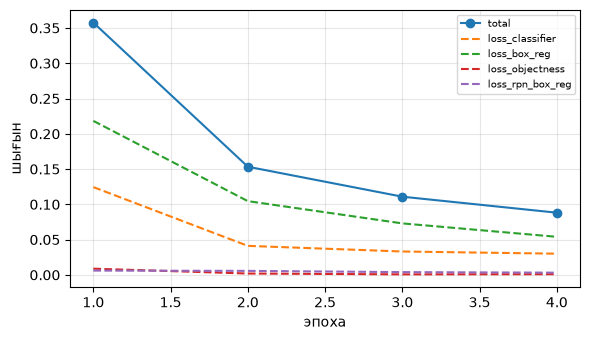

In [4]:
plt.figure(figsize=(6,3.5))
plt.plot(range(1, EPOCHS+1), [h["total"] for h in history], "o-", label="total")
for k in ["loss_classifier", "loss_box_reg", "loss_objectness", "loss_rpn_box_reg"]:
    plt.plot(range(1, EPOCHS+1), [h[k] for h in history], "--", label=k)
plt.xlabel("эпоха"); plt.ylabel("шығын"); plt.legend(fontsize=7); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig("loss.png", dpi=150); plt.show()

## 3 · Бағалау: mAP@0,5, mAP@[.5:.95], TP детекциялардың орташа IoU-ы

In [5]:
@torch.no_grad()
def predict_all(model):
    model.eval(); preds, gts = [], []
    for imgs, tg in val_dl:
        out = model([i.to(device) for i in imgs])
        preds += [{k: v.cpu() for k, v in o.items()} for o in out]
        gts += list(tg)
    return preds, gts

def evaluate(preds, gts, iou_thr=0.5):
    m = MeanAveragePrecision(box_format="xyxy", iou_type="bbox")
    m.update(preds, gts)
    r = m.compute()
    # TP: score>=0.5 детекция, әлі табылмаған GT-мен IoU>=0.5 (ашкөз сәйкестендіру)
    tp_ious = []
    for p, g in zip(preds, gts):
        keep = p["scores"] >= 0.5
        pb = p["boxes"][keep]
        if len(pb) == 0 or len(g["boxes"]) == 0: continue
        iou = box_iou(pb, g["boxes"]); used = set()
        for i in range(len(pb)):            # score кему реті (модель сұрыптаған)
            j = int(iou[i].argmax())
            if iou[i, j] >= iou_thr and j not in used:
                used.add(j); tp_ious.append(float(iou[i, j]))
    return float(r["map_50"]), float(r["map"]), float(np.mean(tp_ious)), len(tp_ious)

preds, gts = predict_all(model)
map50, map_all, miou, ntp = evaluate(preds, gts)
print(f"mAP@0.5       = {map50:.4f}")
print(f"mAP@[.5:.95]  = {map_all:.4f}")
print(f"орташа IoU(TP)= {miou:.4f}  (TP саны: {ntp}, GT саны: {sum(len(g['boxes']) for g in gts)})")

mAP@0.5       = 0.9733
mAP@[.5:.95]  = 0.8112
орташа IoU(TP)= 0.9026  (TP саны: 163, GT саны: 165)


## 4 · NMS табалдырығы (`roi_heads.nms_thresh`)

In [6]:
rows = []
for thr in (0.3, 0.5, 0.7):
    model.roi_heads.nms_thresh = thr
    p, g = predict_all(model)
    rows.append((thr, *evaluate(p, g)))
model.roi_heads.nms_thresh = 0.5
print("nms_thresh | mAP@0.5 | mAP@[.5:.95] | mIoU(TP)")
for r in rows: print(f"   {r[0]:.1f}     |  {r[1]:.4f} |   {r[2]:.4f}     | {r[3]:.4f}")

nms_thresh | mAP@0.5 | mAP@[.5:.95] | mIoU(TP)
   0.3     |  0.9663 |   0.8055     | 0.9036
   0.5     |  0.9733 |   0.8112     | 0.9026
   0.7     |  0.9695 |   0.8083     | 0.9019


## 5 · Қатесі ең көп 4 кадр
Қате = FP + FN саны (score ≥ 0,5, IoU ≥ 0,5). Жасыл — эталон, қызыл — болжам.

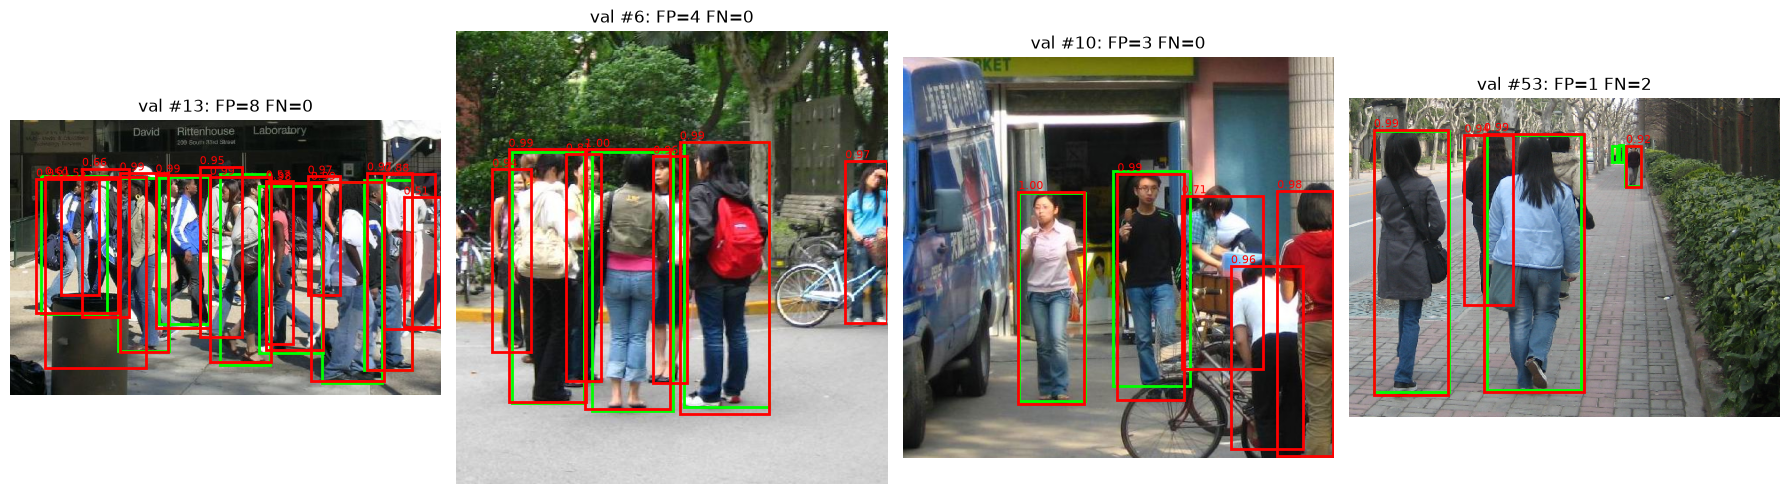

[(13, (8, 8, 0)), (6, (4, 4, 0)), (10, (3, 3, 0)), (53, (3, 1, 2))]


In [7]:
def errors(p, g):
    keep = p["scores"] >= 0.5
    pb = p["boxes"][keep]; gb = g["boxes"]
    if len(pb) == 0: return len(gb), 0, len(gb)
    iou = box_iou(pb, gb); used = set(); tp = 0
    for i in range(len(pb)):
        j = int(iou[i].argmax())
        if iou[i, j] >= 0.5 and j not in used: used.add(j); tp += 1
    fp, fn = len(pb) - tp, len(gb) - tp
    return fp + fn, fp, fn

errs = [errors(p, g) for p, g in zip(preds, gts)]
worst = sorted(range(len(errs)), key=lambda i: -errs[i][0])[:4]
fig, axs = plt.subplots(1, 4, figsize=(18, 5))
for ax, i in zip(axs, worst):
    img, _ = val_ds[i]
    ax.imshow(img.permute(1, 2, 0)); ax.axis("off")
    for b in gts[i]["boxes"]:
        ax.add_patch(patches.Rectangle((b[0], b[1]), b[2]-b[0], b[3]-b[1], fill=False, ec="lime", lw=2))
    for b, s in zip(preds[i]["boxes"], preds[i]["scores"]):
        if s >= 0.5:
            ax.add_patch(patches.Rectangle((b[0], b[1]), b[2]-b[0], b[3]-b[1], fill=False, ec="red", lw=2))
            ax.text(b[0], b[1], f"{s:.2f}", color="red", fontsize=8, va="bottom")
    e = errs[i]; ax.set_title(f"val #{i}: FP={e[1]} FN={e[2]}")
plt.tight_layout(); plt.savefig("worst4.png", dpi=130); plt.show()
print([(i, errs[i]) for i in worst])